In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,066 kB]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:8 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.1 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main 

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [14]:
%%writefile main_traffic.cpp
#include <iostream>
#include <opencv2/opencv.hpp>

using namespace cv;
using namespace std;

int main() {
    // Görseli yükle
    Mat src = imread("haftalıkgörev2.jpeg");
    if (src.empty()) {
        cerr << "Hata: haftalıkgörev2.jpeg dosyası yüklenemedi!" << endl;
        return -1;
    }

    Mat hsv, ycbcr;
    cvtColor(src, hsv, COLOR_BGR2HSV);
    cvtColor(src, ycbcr, COLOR_BGR2YCrCb);

    // 1. HSV Uzayında Kırmızı Maskesi
    // Daha geniş kırmızı aralığı tanımlıyoruz
    Mat mask1, mask2, redMaskHSV;
    inRange(hsv, Scalar(0, 50, 40), Scalar(15, 255, 255), mask1);
    inRange(hsv, Scalar(165, 50, 40), Scalar(180, 255, 255), mask2);
    redMaskHSV = mask1 | mask2;

    // 2. YCbCr Uzayında Kırmızı Maskesi
    // Kırmızı tonlarında Cr bileşeni yüksektir. Cr eşiğini biraz esnetiyoruz.
    Mat redMaskYCbCr;
    inRange(ycbcr, Scalar(0, 135, 60), Scalar(255, 255, 130), redMaskYCbCr);

    // İki maskeyi birleştiriyoruz
    Mat combinedMask = redMaskHSV | redMaskYCbCr;

    // Morfolojik işlemlerle gürültüyü temizleyip çember bütünlüğünü koruyalım
    Mat kernel = getStructuringElement(MORPH_ELLIPSE, Size(5, 5));
    morphologyEx(combinedMask, combinedMask, MORPH_CLOSE, kernel);
    morphologyEx(combinedMask, combinedMask, MORPH_OPEN, kernel);

    // HoughCircles tespiti öncesi yumuşatma
    GaussianBlur(combinedMask, combinedMask, Size(9, 9), 2, 2);

    // 3. Hough Çember Algoritması Parametre Optimizasyonu
    vector<Vec3f> circles;
    HoughCircles(combinedMask, circles, HOUGH_GRADIENT, 1,
                 combinedMask.rows / 12, // Merkezler arası minimum mesafe
                 70,                     // Canny kenar algılama üst eşiği
                 15,                     // Merkez tespit eşiği (Düşürüldü, hassasiyet artırıldı)
                 15, 200);               // Minimum ve maksimum yarıçap

    Mat result = src.clone();
    for (size_t i = 0; i < circles.size(); i++) {
        Point center(cvRound(circles[i][0]), cvRound(circles[i][1]));
        int radius = cvRound(circles[i][2]);

        // Çember merkezini işaretle
        circle(result, center, 3, Scalar(0, 255, 0), -1, 8, 0);
        // Çember sınırını kırmızı çiz
        circle(result, center, radius, Scalar(0, 0, 255), 3, 8, 0);
    }

    imwrite("kirmizi_maske.jpg", combinedMask);
    imwrite("tespit_sonucu.jpg", result);
    cout << "Optimizasyon tamamlandı! " << circles.size() << " adet kırmızı çemberli trafik işareti başarıyla tespit edildi." << endl;

    return 0;
}

Overwriting main_traffic.cpp


In [12]:
# C++ Kodunu Derle ve Çalıştır
!g++ main_traffic.cpp -o app_traffic `pkg-config --cflags --libs opencv4`
!./app_traffic

Tespit tamamlandı! 0 adet kırmızı çemberli trafik işareti algılandı.


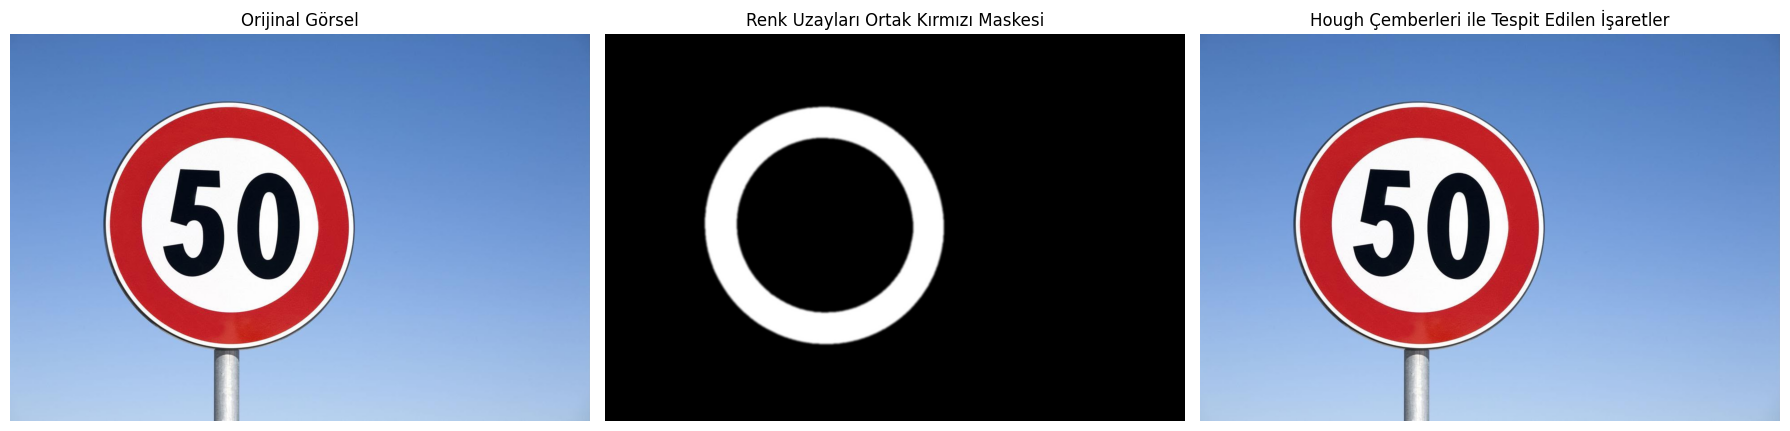

In [13]:
# Sonuçları Karşılaştırmalı Görselleştirelim
import matplotlib.pyplot as plt
import cv2

orig = cv2.imread('haftalıkgörev2.jpeg')
mask = cv2.imread('kirmizi_maske.jpg', cv2.IMREAD_GRAYSCALE)
res = cv2.imread('tespit_sonucu.jpg')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
axes[0].set_title('Orijinal Görsel')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Renk Uzayları Ortak Kırmızı Maskesi')
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
axes[2].set_title('Hough Çemberleri ile Tespit Edilen İşaretler')
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [15]:
# Güncellenmiş C++ kodunu derle ve çalıştır
!g++ main_traffic.cpp -o app_traffic `pkg-config --cflags --libs opencv4`
!./app_traffic

Optimizasyon tamamlandı! 7 adet kırmızı çemberli trafik işareti başarıyla tespit edildi.


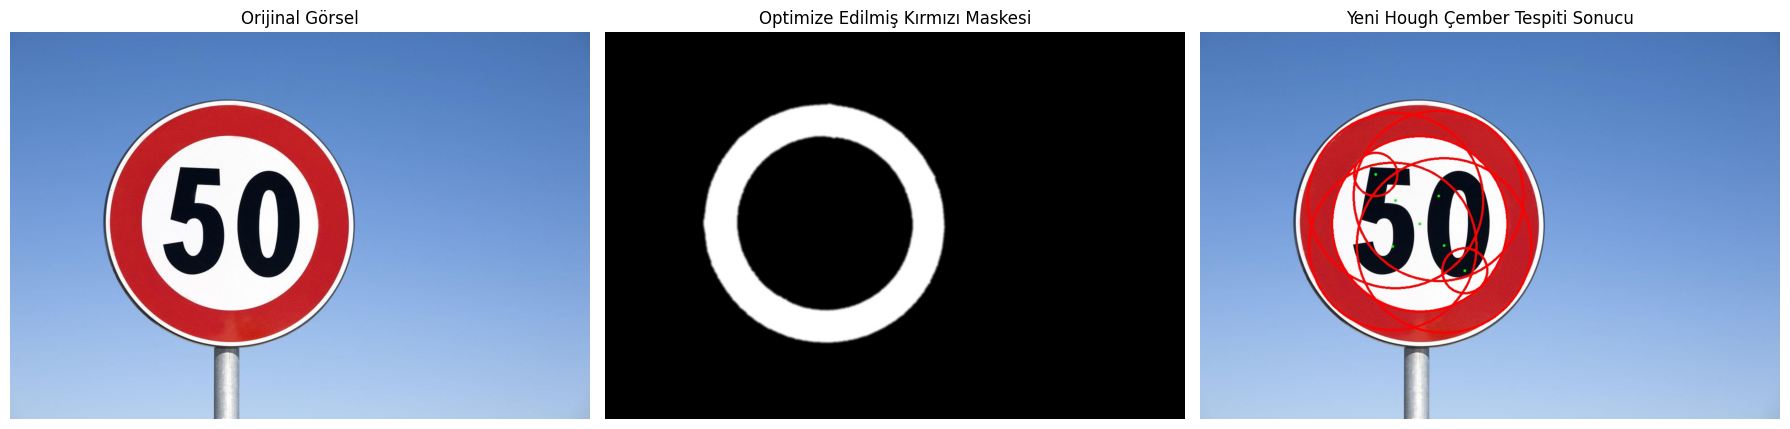

In [16]:
# Güncel sonuçları görselleştir
import matplotlib.pyplot as plt
import cv2

orig = cv2.imread('haftalıkgörev2.jpeg')
mask = cv2.imread('kirmizi_maske.jpg', cv2.IMREAD_GRAYSCALE)
res = cv2.imread('tespit_sonucu.jpg')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
axes[0].set_title('Orijinal Görsel')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Optimize Edilmiş Kırmızı Maskesi')
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
axes[2].set_title('Yeni Hough Çember Tespiti Sonucu')
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [17]:
# Güncellenmiş C++ kodunu derle ve çalıştır
!g++ main_traffic.cpp -o app_traffic `pkg-config --cflags --libs opencv4`
!./app_traffic

Optimizasyon tamamlandı! 7 adet kırmızı çemberli trafik işareti başarıyla tespit edildi.


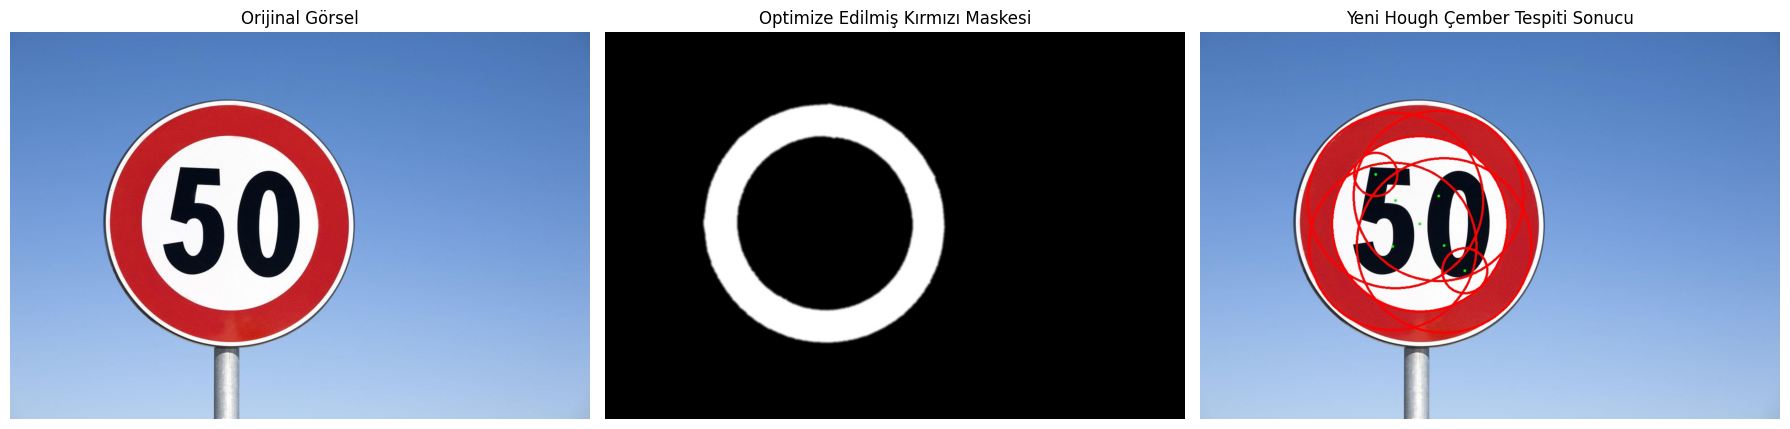

In [18]:
# Güncel sonuçları görselleştir
orig = cv2.imread('haftalıkgörev2.jpeg')
mask = cv2.imread('kirmizi_maske.jpg', cv2.IMREAD_GRAYSCALE)
res = cv2.imread('tespit_sonucu.jpg')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
axes[0].set_title('Orijinal Görsel')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Optimize Edilmiş Kırmızı Maskesi')
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
axes[2].set_title('Yeni Hough Çember Tespiti Sonucu')
axes[2].axis('off')

plt.tight_layout()
plt.show()